# High Dimensional Data & The Curse of Dimensionality

![](img/banner.png)

Computer Science Dept, Ferdowsi University of Mashhad

## Introduction

In modern data mining and machine learning, we often deal with data in very high-dimensional spaces (e.g., images, text embeddings, genomic data). A dataset is typically represented as an $n \times d$ matrix $\mathbf{D}$.

Understanding the nature of high-dimensional space, or **hyperspace**, is very important because it does not behave like the more familiar geometry in two or three dimensions. This phenomenon is often referred to as the **Curse of Dimensionality**.

Key phenomena we will explore:
1.  **Volume Concentration:** The volume of a hypersphere vanishes relative to the hypercube.
2.  **The Problem of Local Neighborhoods:** Why "local" methods like k-NN fail (based on *Elements of Statistical Learning*).
3.  **The Thin Shell:** Most of the volume concentrates near the surface (measured on the [sampling page](High-Dimensional-Sampling.ipynb)).
4.  **Orthogonality:** Random vectors in high dimensions are nearly orthogonal.
5.  **Gaussian Behavior:** Points concentrate in a thin ring around radius $\sqrt{d}$ — also measured on the [sampling page](High-Dimensional-Sampling.ipynb).

---

## Geometry of Hyperspace: Cubes and Spheres

Let's define the two most basic shapes in $d$-dimensions.

### The Hypercube
The data space is often viewed as a $d$-dimensional hyper-rectangle or hypercube.
For a hypercube $H_d(l)$ with side length $l$, the volume is:

$$\text{Vol}(H_d(l)) = l^d$$

### The Hypersphere
We write $B_d(r)$ for the **solid** ball and $S_d(r)$ for its **surface**. The distinction matters: the volume below is a property of the ball, and its boundary is a single layer of measure zero. The volume of the $d$-dimensional ball of radius $r$ is:

$$\text{Vol}(S_d(r)) = K_d r^d = \frac{\pi^{d/2}}{\Gamma(\frac{d}{2}+1)} r^d$$

Where $\Gamma$ is the Gamma function.

![](img/Figure-6.4-Zaki.png)
Figure 6.4. Hypersphere inscribed inside a hypercube: in (a) two and (b) three dimensions

### The Empty Center (The "Porcupine" Effect)
Consider the space enclosed within the largest hypersphere that can be accommodated within a hypercube of side length $l=2r$.
The ratio of their volumes is:

$$\lim_{d \to \infty} \frac{\text{Vol}(S_d(r))}{\text{Vol}(H_d(2r))} = \lim_{d \to \infty} \frac{\pi^{d/2}}{2^d \Gamma(\frac{d}{2}+1)} \to 0$$

**Implication:** As dimensionality increases, the volume of the hypersphere becomes negligible compared to the hypercube. Most of the volume of the hypercube is in the **corners**, whereas the center is essentially empty.

![Corners in High Dimension](img/Figure-6.5-Zaki.png)

Conceptual view of high-dimensional space: (a) two, (b) three, (c) four, and (d) higher
dimensions. In d dimensions there are $2^d$ “corners” and $2^{d−1}$ diagonals. The radius of the inscribed circle accurately reflects the difference between the volume of the hypercube and the inscribed hypersphere in $d$ dimensions.

---

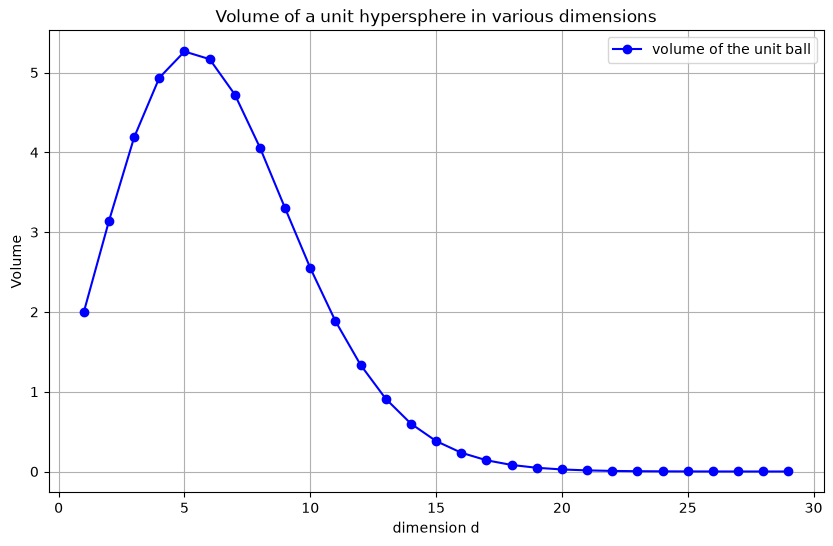

In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
def hypersphere_volume(d, R):
    """Volume of the solid ball of radius R in d dimensions."""
    return (math.pi ** (d / 2)) * (R ** d) / math.gamma(d / 2 + 1)


dimensions = list(range(1, 30))
volumes = [hypersphere_volume(d,1) for d in dimensions]
plt.figure(figsize=(10, 6))
plt.plot(dimensions, volumes, marker='o', linestyle='-', color='b', label='volume of the unit ball')
plt.xlabel('dimension d')
plt.ylabel('Volume')
plt.title("Volume of a unit hypersphere in various dimensions")
plt.legend()
plt.grid(True)
plt.show()


## The Problem of Local Neighborhoods (k-NN)

One of the most significant manifestations of the curse of dimensionality affects "local" methods like k-Nearest Neighbors (k-NN).

### Edge Length of Neighborhoods
Suppose we have inputs uniformly distributed in a $p$-dimensional unit hypercube. We want to form a local neighborhood that captures a fraction $r$ of the observations.
Since this corresponds to a fraction of the unit volume, the expected edge length $e_p(r)$ of this neighborhood is:

$$e_p(r) = r^{1/p}$$

![](img/Figure-2.6-ESL.png)

FIGURE 2.6. The curse of dimensionality is well illustrated by a subcubical
neighborhood for uniform data in a unit cube. The figure on the right shows the
side-length of the subcube needed to capture a fraction r of the volume of the data,
for different dimensions p. In ten dimensions we need to cover 80% of the range
of each coordinate to capture 10% of the data

Let's visualize this for different dimensions ($p$) and fractions ($r$).

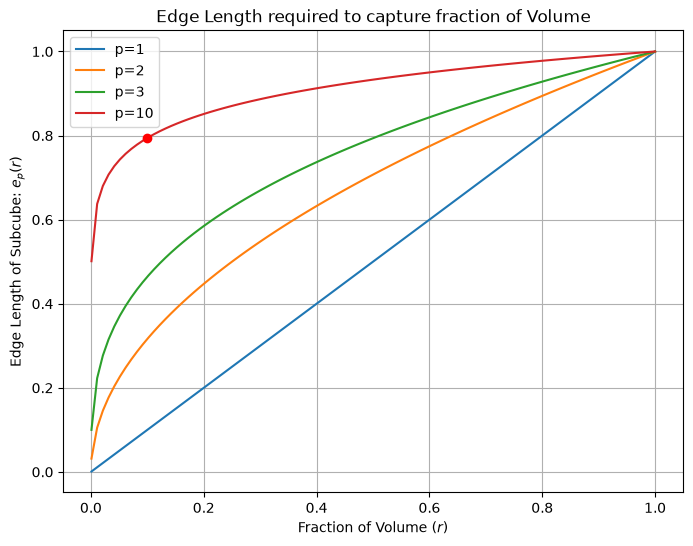

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def edge_length(fraction_volume, p):
    return fraction_volume ** (1/p)

fractions = np.linspace(0.001, 1.0, 100)
dims_esl = [1, 2, 3, 10]

plt.figure(figsize=(8, 6))
for p in dims_esl:
    plt.plot(fractions, edge_length(fractions, p), label=f'p={p}')

# Highlighting the case for p=10, r=0.1
plt.plot(0.1, 0.1**(1/10), 'ro') 

plt.xlabel('Fraction of Volume ($r$)')
plt.ylabel('Edge Length of Subcube: $e_p(r)$')
plt.title('Edge Length required to capture fraction of Volume')
plt.legend()
plt.grid(True)
plt.show()


**Analysis:**
In 10 dimensions ($p=10$), to capture just **10%** ($r=0.1$) of the data, we need to cover **80%** of the range of each input variable.
Such neighborhoods are no longer "local". To find neighbors, we must look very far away.

### Distance to Boundary

Another consequence is that sampling density is sparse. For $N$ data points in a $p$-dimensional unit ball, the median distance from the origin to the closest data point is:

$$ d(p,N) = \left(1 - \left(\tfrac{1}{2}\right)^{1/N}\right)^{1/p} $$

For $N=500$ and $p=10$, this distance is $\approx 0.52$, which is more than halfway to the boundary. Hence, **most data points are closer to the boundary of the sample space than to any other data point**. This makes prediction a problem of *extrapolation* rather than *interpolation*.

-----


-----

## Orthogonality: Random Directions Are Nearly Perpendicular

Another counter-intuitive property: in high dimension every direction is nearly orthogonal to every other direction. Two vectors drawn at random are almost always almost perpendicular.

### The diagonal of the cube versus an axis

Consider the diagonal vector in a hypercube $\mathbf{1} = (1, 1, \dots, 1)^T$. The angle $\theta_d$ between this diagonal and any coordinate axis $\mathbf{e}_1 = (1, 0, \dots, 0)^T$ is:

$$ \cos \theta_d = \frac{\mathbf{e}_1^T \mathbf{1}}{||\mathbf{e}_1|| \cdot ||\mathbf{1}||} = \frac{1}{1 \cdot \sqrt{d}} = \frac{1}{\sqrt{d}} $$

As $d \to \infty$, $\cos \theta_d \to 0$, which means $\theta_d \to 90^\circ$. The diagonal is effectively orthogonal to the axes\!

Furthermore, **random vectors** in high dimensions are nearly orthogonal to each other.

In [3]:
dim = 200
# Generate random vectors
x = np.random.randn(4, dim)
# Normalize
x_norm = x / np.linalg.norm(x, axis=1)[:, np.newaxis]

print(f"Dot products of random pairs in {dim}-D:")
for i in range(len(x_norm)):
    for j in range(i+1, len(x_norm)):
        dp = np.dot(x_norm[i], x_norm[j])
        print(f"Vector {i} . Vector {j} = {dp:.4f}")

Dot products of random pairs in 200-D:
Vector 0 . Vector 1 = -0.0227
Vector 0 . Vector 2 = 0.0015
Vector 0 . Vector 3 = 0.0229
Vector 1 . Vector 2 = -0.0327
Vector 1 . Vector 3 = 0.0843
Vector 2 . Vector 3 = 0.0176



### Summary

  * High-dimensional space is **empty** in the center.
  * Volume is in the **corners** or a **thin shell** at the surface.
  * **Neighbors** are far away (breaking local methods like k-NN).
  * Random vectors are **orthogonal**.

The computations behind these statements — the shell volume, rejection sampling,
uniform points on the sphere and inside the ball, and the Gaussian annulus — are on
[Sampling in High Dimensional Spaces](High-Dimensional-Sampling.ipynb).

### References

1.  {cite}`zaki2020data`, Chapter 6 (high-dimensional space).
2.  Blum, A., Hopcroft, J., & Kannan, R. (2020). *Foundations of Data Science*. Cambridge University Press.
3.  Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*.


## Exercises

1. Compute the ratio of the volume of the unit ball to the volume of the cube $[-1,1]^d$ for $d=2,10,100$. At which dimension does the ball hold less than $1\%$ of the cube?
2. For two random unit vectors in $\mathbb{R}^d$, show that $\mathbb{E}[\cos^2\theta]=1/d$ and plot the histogram of $\cos\theta$ for $d=2$ and $d=100$. What does the concentration mean for the words nearest and farthest?
3. Compute the fraction of the ball's volume in the shell $0.9\le r\le 1$ as a function of $d$, and explain the consequence for sampling points uniformly in a high-dimensional ball.
4. Using the notebook's neighbourhood argument, show that the edge length of a cube holding a fixed fraction $p$ of the points grows like $p^{1/d}$, and evaluate it for $p=0.01$ and $d=100$.

